John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

In [114]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    # "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [115]:
# load packages
install.packages("tidyverse")
library(tidyverse)
library(tidymodels)
theme_dark()
# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' is in use and will not be installed"


<theme> List of 144
 $ line                            : <ggplot2::element_line>
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ lineend      : chr "butt"
  ..@ linejoin     : chr "round"
  ..@ arrow        : logi FALSE
  ..@ arrow.fill   : chr "black"
  ..@ inherit.blank: logi TRUE
 $ rect                            : <ggplot2::element_rect>
  ..@ fill         : chr "white"
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ linejoin     : chr "round"
  ..@ inherit.blank: logi TRUE
 $ text                            : <ggplot2::element_text>
  ..@ family       : chr ""
  ..@ face         : chr "plain"
  ..@ italic       : chr NA
  ..@ fontweight   : num NA
  ..@ fontwidth    : num NA
  ..@ colour       : chr "black"
  ..@ size         : num 11
  ..@ hjust        : num 0.5
  ..@ vjust        : num 0.5
  ..@ angle        : num 0
  ..@ lineheight   : num 0.9
  ..@ margin       : <ggplot2::margin> nu

In [116]:
# Fall 2026 results

test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

test_accuracies <- bind_rows(test_accuracies)
song_accuracies <- bind_rows(song_accuracies)

test_accuracies <- song_accuracies %>% group_by(ID) %>% summarize(repertoire_size = n_distinct(UST)) %>% 
    full_join(test_accuracies, by=join_by(ID)) %>%
    left_join(focal_males, by="ID")

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/candidate_match_distance_weighted_window60_ablation.csv"
[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/candidate_match_distance_weighted_window60_ablation1_barchart.png"
[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_All_neighbour_features_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_All_neighbour_features_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (2): estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Baseline_most_common_song_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (30 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Song_type_rates_song_accuracies.csv"


Rows: 192 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\2026_results/logit_Song_type_rates_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (2): estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [117]:
# Winter 2026 Results (last semester)

test_accuracies_2026 <- list()
song_accuracies_2026 <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies_2026 <- append(test_accuracies_2026, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies_2026 <- append(song_accuracies_2026, list("{file}" = read_csv(file)))
    }
}

test_accuracies_2026 <- bind_rows(test_accuracies_2026)
song_accuracies_2026 <- bind_rows(song_accuracies_2026)

test_accuracies_2026 <- song_accuracies_2026 %>% group_by(ID) %>% summarize(repertoire_size = n_distinct(UST)) %>% 
    full_join(test_accuracies_2026, by=join_by(ID)) %>%
    left_join(focal_males, by="ID")

# Select only models featured in Winter 2026 report
report_models_2026 <- c(
    "Baseline Classifier",
    # "Own Song History",
    "Own Last Songs",
    "Last Song from Each Neighbour",
    "All songs since last own song",
    "All songs in last 60s",
    "Attention",
    "Attention 30s",
    "Most Common Songs"
)

test_accuracies_2026 <- test_accuracies_2026 %>% filter(model %in% report_models_2026)
song_accuracies_2026 <- song_accuracies_2026 %>% filter(model %in% report_models_2026)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Baseline Classifier_test_accuracies.csv"


Rows: 10 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/gb_ablation_song_accuracies.csv"


Rows: 1701 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/gb_ablation_test_accuracies.csv"


... (57 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/rf_True Attention_test_accuracies.csv"


Rows: 11 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes Baseline Classifier_test_accuracies.csv"


Rows: 10 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, model, model_type
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message in left_join(., focal_males, by = "ID"):
"Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 5 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning."


In [118]:
test_accuracies %>% pull(model) %>% unique()

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

In [119]:
# report_models <- c(
#     "Baseline Classifier",
#     "Own Song History",
#     "Own Last Songs",
#     "Last Song from Each Neighbour",
#     "All songs since last own song",
#     "All songs in last 60s",
#     "Attention",
#     "Attention 30s",
#     "Most Common Songs"
# )
report_models <- unique(song_accuracies$model)

In [120]:
c(report_models)

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

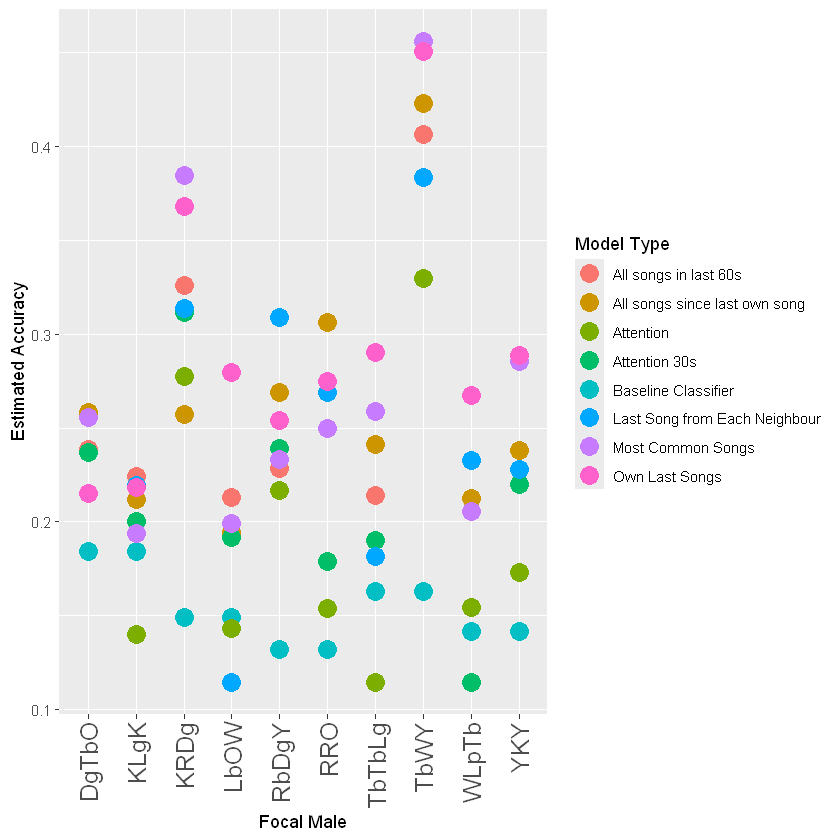

In [121]:
plot <- ggplot(data = test_accuracies_2026 %>% filter(model %in% report_models_2026 & ID != "OPR") %>% filter(model_type %in% c("Baseline", "Random Forest")), aes(x=ID, y=estimated_accuracy, color=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Focal Male", y= "Estimated Accuracy", colour="Model Type")
print(plot)

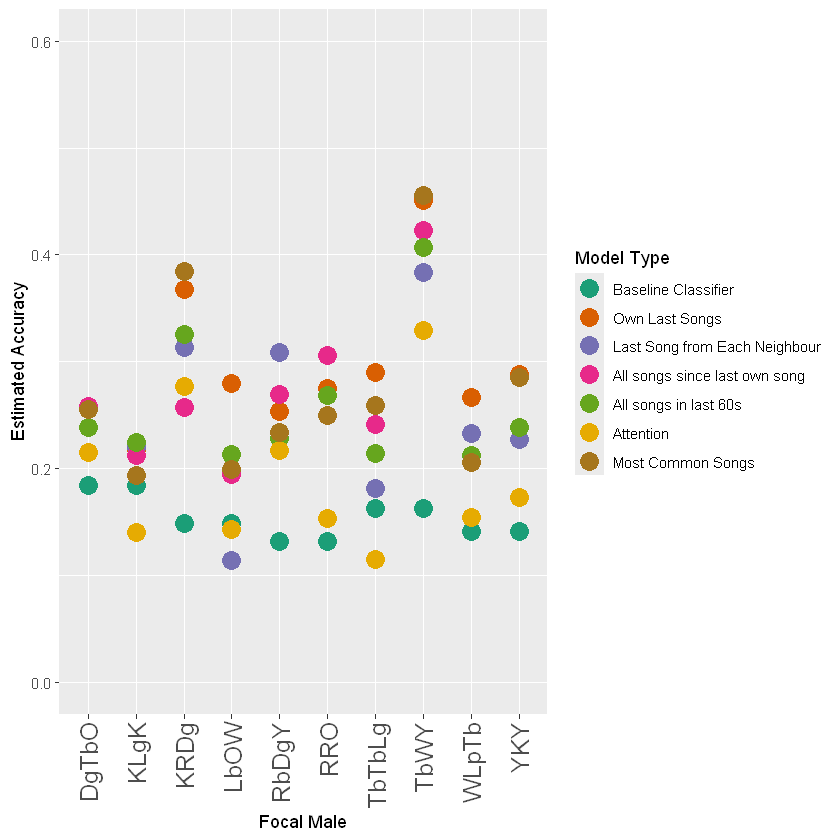

In [122]:
model_order <- c(
  "Baseline Classifier",
  "Own Last Songs",
  "Last Song from Each Neighbour",
  "All songs since last own song",
  "All songs in last 60s",
  "Attention",
  "Most Common Songs"
)

model_colors <- c(
  "Baseline Classifier" = "#1B9E77",
  "Own Last Songs" = "#D95F02",
  "Last Song from Each Neighbour" = "#7570B3",
  "All songs since last own song" = "#E7298A",
  "All songs in last 60s" = "#66A61E",
  "Attention" = "#E6AB02",
  "Most Common Songs" = "#A6761D"
)

plot_data <- test_accuracies_2026 %>%
  filter(
    model %in% 
    # c("Baseline Classifier"),
    # c("Baseline Classifier", "Own Last Songs"),
    model_order,
    ID != "OPR",
    model_type %in% c("Baseline", "Random Forest")
  ) %>%
  mutate(model = factor(model, levels = model_order)) %>%
  arrange(model)

plot <- ggplot(
  plot_data,
  aes(x = ID, y = estimated_accuracy, color = model)
) +
  geom_point(size = 5) +
  scale_color_manual(
    values = model_colors,
    limits = model_order
  ) +
  theme(
    axis.text.x = element_text(
      angle = 90, vjust = 0.5, hjust = 1, size = 15
    )
  ) +
  labs(
    x = "Focal Male",
    y = "Estimated Accuracy",
    colour = "Model Type"
  ) +
  ylim(0, 0.6)

print(plot)

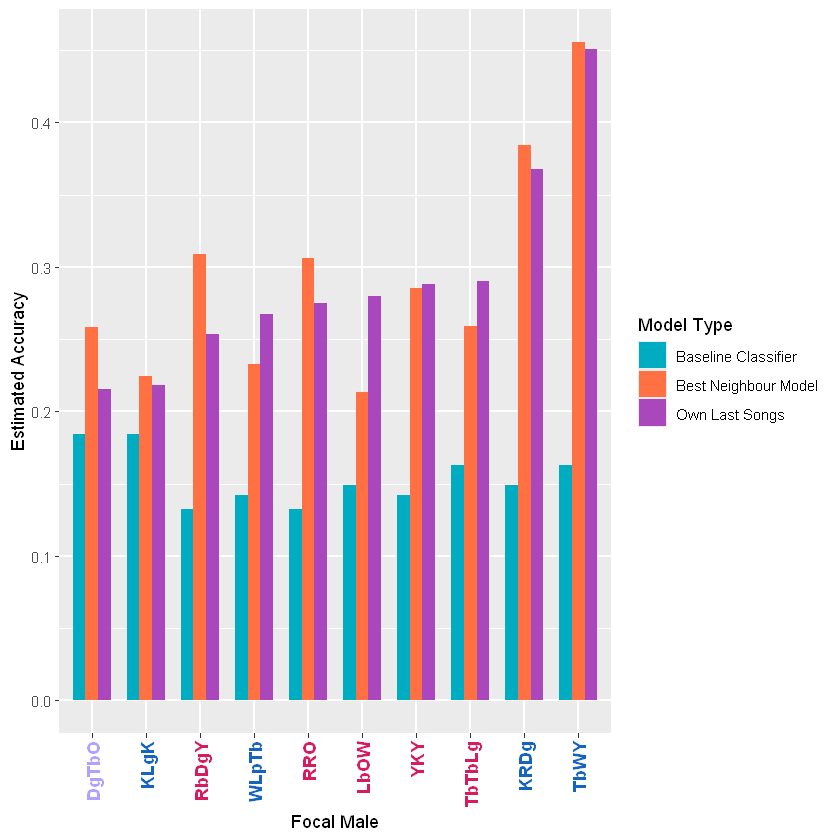

In [123]:
library(tidyverse)

# 1. Prepare Baseline and Own Last Songs data
base_ols <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(model %in% c("Baseline Classifier", "Own Last Songs")) %>%
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 2. Find the highest accuracy alternative model per focal male (excluding Baseline, Own Last Songs, AND Own Song History)
highest_other <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(!model %in% c("Baseline Classifier", "Own Last Songs", "Own Song History")) %>%
  filter(model_type %in% c("Baseline", "Random Forest")) %>%
  group_by(ID) %>%
  slice_max(estimated_accuracy, n = 1, with_ties = FALSE) %>%
  mutate(model = "Best Neighbour Model") %>% 
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 3. Combine into the final plotting dataset
plot_data <- bind_rows(base_ols, highest_other)

# 4. Sort by Baseline Classifier accuracy
baseline_order <- base_ols %>%
  filter(model == "Own Last Songs") %>%
  group_by(ID) %>%
  summarise(
    baseline_accuracy = max(estimated_accuracy, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(baseline_accuracy, ID) %>%
  pull(ID)

plot_data <- plot_data %>%
  mutate(ID = factor(ID, levels = baseline_order))

# 5. Define custom fill colors for the 3 model types
custom_colors <- c(
  "Baseline Classifier" = "#00ACC1",     # Teal/cyan tone
  "Own Last Songs" = "#AB47BC",         # Purple tone
  "Best Neighbour Model" = "#FF7043"    # Coral/orange tone
)

# 6. Create a named color vector for the X-axis labels based on neighborhood
# Adjust the hex codes below for North, Centre, and DgTbO to your preference:
label_colors <- c(
  "north"   = "#D81B60",  # Dark Green for North
  "centre"  = "#1565C0",  # Dark Blue for Centre
  "Both"    = "#afa1ff"   # Distinct Magenta/Pink for DgTbO (Both)
)

# Map each ID to its respective neighborhood category for the axis coloring
# (Assumes 'neighbourhood' column exists in your dataframe; DgTbO is explicitly caught)
id_neighborhoods <- plot_data %>%
  distinct(ID, neighbourhood) %>%
  mutate(
    label_group = case_when(
      ID == "DgTbO" ~ "Both",
      neighbourhood == "north" ~ "north",
      neighbourhood == "centre" ~ "centre",
      TRUE ~ "north" # Fallback if needed
    )
  )

# Order the colors to match the current factor levels of ID
axis_text_colors <- id_neighborhoods %>%
  slice(match(levels(plot_data$ID), ID)) %>%
  pull(label_group)
  
axis_colors_named <- label_colors[axis_text_colors]

# 7. Generate the styled bar chart with colored x-axis labels
ggplot(plot_data, aes(x = ID, y = estimated_accuracy, fill = model)) +
  geom_col(position = "dodge", width = 0.7) +
  scale_fill_manual(values = custom_colors) +
  theme_grey() +
  labs(
    x = "Focal Male",
    y = "Estimated Accuracy",
    fill = "Model Type"
  ) +
  theme(
    axis.text.x = element_text(
      angle = 90, 
      vjust = 0.5, 
      hjust = 1, 
      size = 11, 
      color = axis_colors_named, # Applies individual neighborhood colors here
      face = "bold"
    ),
    panel.grid.major = element_line(color = "white", linewidth = 0.8),
    panel.grid.minor = element_line(color = "white", linewidth = 0.4),
    legend.position = "right"
  )

In [124]:
test_accuracies_2026 %>% pull(model) %>% unique()

[1] "Baseline Classifier"           "All songs in last 60s"        
[3] "All songs since last own song" "Attention 30s"                
[5] "Attention"                     "Most Common Songs"            
[7] "Own Last Songs"                "Last Song from Each Neighbour"

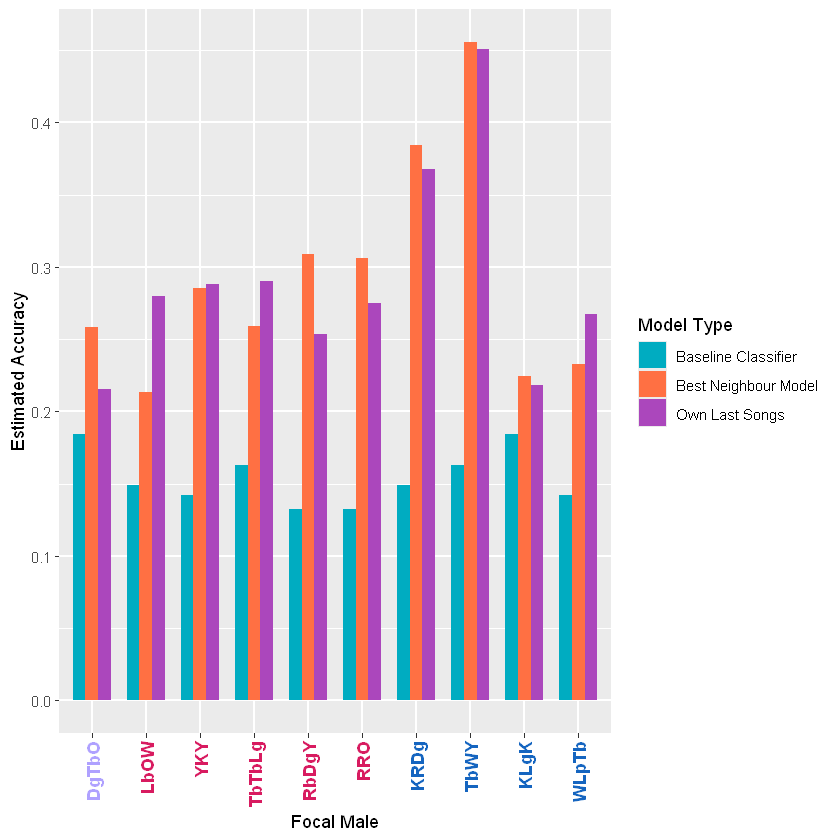

In [125]:
library(tidyverse)

# 1. Prepare Baseline and Own Last Songs data
base_ols <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(model %in% c("Baseline Classifier", "Own Last Songs")) %>%
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 2. Find the highest accuracy alternative model per focal male (excluding Baseline, Own Last Songs, AND Own Song History)
highest_other <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(!model %in% c("Baseline Classifier", "Own Last Songs", "Own Song History")) %>%
  filter(model_type %in% c("Baseline", "Random Forest")) %>%
  group_by(ID) %>%
  slice_max(estimated_accuracy, n = 1, with_ties = FALSE) %>%
  mutate(model = "Best Neighbour Model") %>% 
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 3. Combine into the final plotting dataset
plot_data <- bind_rows(base_ols, highest_other)

# 4. Order IDs from least to most mean distance from neighbour (DgTbO placed at end due to missing value)
distance_order <- c(
  "DgTbO",   # Blank in table
  "LbOW",   # 67.4 m
  "YKY",    # 69.8 m
  "TbTbLg", # 85.1 m
  "RbDgY",  # 97.7 m
  "RRO",    # 98.4 m
  "KRDg",   # 101.9 m
  "TbWY",   # 116.8 m
  "KLgK",   # 131.3 m
  "WLpTb"  # 139.7 m
)

plot_data <- plot_data %>%
  mutate(ID = factor(ID, levels = distance_order))

# 5. Define custom fill colors for the 3 model types
custom_colors <- c(
  "Baseline Classifier" = "#00ACC1",     # Teal/cyan tone
  "Own Last Songs" = "#AB47BC",         # Purple tone
  "Best Neighbour Model" = "#FF7043"    # Coral/orange tone
)

# 6. Set distinct colors for north, centre, and Both (DgTbO)
label_colors <- c(
  "north"   = "#D81B60",  # Dark Green for North
  "centre"  = "#1565C0",  # Dark Blue for Centre
  "Both"    = "#afa1ff"   # Distinct Magenta/Pink for DgTbO (Both)
)

# Map each ID to its exact neighborhood category, handling DgTbO separately
id_neighborhoods <- plot_data %>%
  distinct(ID, .keep_all = TRUE) %>%
  mutate(
    label_group = case_when(
      ID == "DgTbO" ~ "Both",
      neighbourhood == "north" ~ "north",
      neighbourhood == "centre" ~ "centre",
      TRUE ~ as.character(neighbourhood)
    )
  )

# Align the colors with the current factor order of the x-axis
axis_text_colors <- id_neighborhoods %>%
  slice(match(levels(plot_data$ID), ID)) %>%
  pull(label_group)
  
axis_colors_named <- label_colors[axis_text_colors]

# 7. Generate the styled bar chart
ggplot(plot_data, aes(x = ID, y = estimated_accuracy, fill = model)) +
  geom_col(position = "dodge", width = 0.7) +
  scale_fill_manual(values = custom_colors) +
  theme_grey() +
  labs(
    x = "Focal Male",
    y = "Estimated Accuracy",
    fill = "Model Type"
  ) +
  theme(
    axis.text.x = element_text(
      angle = 90, 
      vjust = 0.5, 
      hjust = 1, 
      size = 11, 
      color = axis_colors_named,
      face = "bold"
    ),
    panel.grid.major = element_line(color = "white", linewidth = 0.8),
    panel.grid.minor = element_line(color = "white", linewidth = 0.4),
    legend.position = "right"
  )

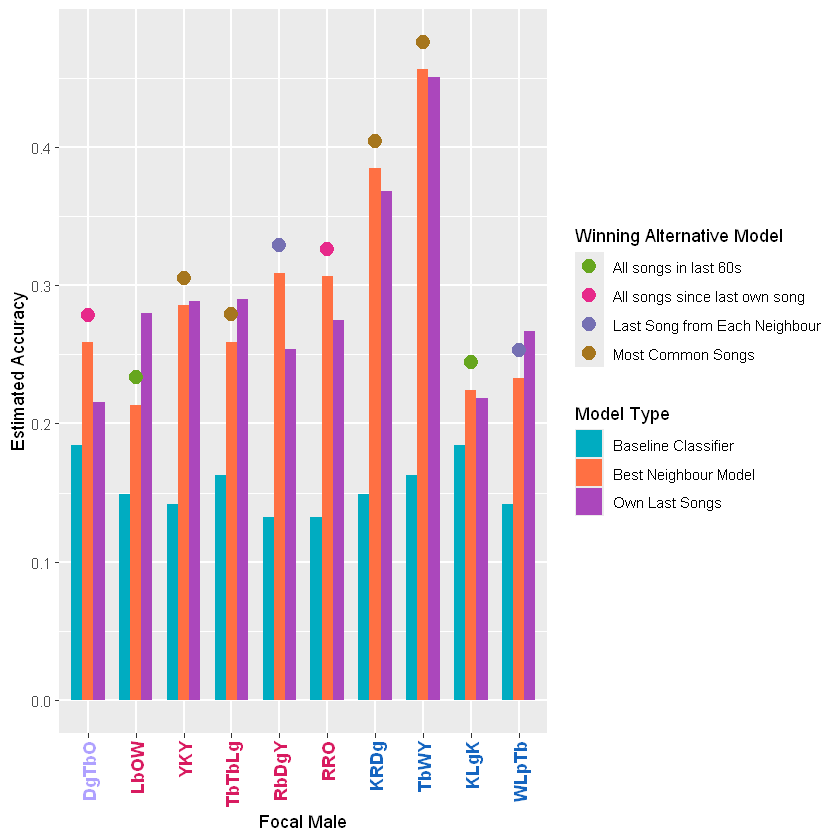

In [126]:
library(tidyverse)

# 1. Prepare Baseline and Own Last Songs data
base_ols <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(model %in% c("Baseline Classifier", "Own Last Songs")) %>%
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 2. Find the highest accuracy alternative model per focal male AND keep its specific name for the dots
highest_other_raw <- test_accuracies_2026 %>% filter(ID != "OPR") %>%
  filter(!model %in% c("Baseline Classifier", "Own Last Songs", "Own Song History")) %>%
  filter(model_type %in% c("Baseline", "Random Forest")) %>%
  group_by(ID) %>%
  slice_max(estimated_accuracy, n = 1, with_ties = FALSE)

# Extract the specific winning model name for each male (for the dots)
dot_data <- highest_other_raw %>%
  ungroup() %>%
  mutate(
    specific_model = model,
    model = "Best Neighbour Model"
  )

# Create the plotting dataset for the bars
highest_other <- dot_data %>%
  select(ID, neighbourhood, male_number, model, estimated_accuracy)

# 3. Combine into the final plotting dataset
plot_data <- bind_rows(base_ols, highest_other)

# 4. Order IDs from least to most mean distance from neighbour
distance_order <- c(
  "DgTbO",   # Blank in table
  "LbOW",    # 67.4 m
  "YKY",     # 69.8 m
  "TbTbLg",  # 85.1 m
  "RbDgY",   # 97.7 m
  "RRO",     # 98.4 m
  "KRDg",    # 101.9 m
  "TbWY",    # 116.8 m
  "KLgK",    # 131.3 m
  "WLpTb"    # 139.7 m
)

plot_data <- plot_data %>%
  mutate(ID = factor(ID, levels = distance_order))

dot_data <- dot_data %>%
  mutate(ID = factor(ID, levels = distance_order))

# 5. Define custom fill colors for the 3 main model types (Fixes the gray bars)
custom_colors <- c(
  "Baseline Classifier" = "#00ACC1",     # Teal/cyan tone
  "Own Last Songs" = "#AB47BC",         # Purple tone
  "Best Neighbour Model" = "#FF7043"    # Coral/orange tone
)

# 6. Define distinct colors for ALL potential winning alternative models (for the dots)
winning_model_colors <- c(
  "Baseline Classifier" = "#1B9E77",
  "Own Last Songs" = "#D95F02",
  "Last Song from Each Neighbour" = "#7570B3",
  "All songs since last own song" = "#E7298A",
  "All songs in last 60s" = "#66A61E",
  "Attention" = "#E6AB02",
  "Most Common Songs" = "#A6761D"
)

# 7. Set distinct colors for north, centre, and Both (DgTbO)
label_colors <- c(
  "north"   = "#D81B60",  # North color
  "centre"  = "#1565C0",  # Centre color
  "Both"    = "#afa1ff"   # DgTbO color
)

id_neighborhoods <- plot_data %>%
  distinct(ID, .keep_all = TRUE) %>%
  mutate(
    label_group = case_when(
      ID == "DgTbO" ~ "Both",
      neighbourhood == "north" ~ "north",
      neighbourhood == "centre" ~ "centre",
      TRUE ~ as.character(neighbourhood)
    )
  )

axis_text_colors <- id_neighborhoods %>%
  slice(match(levels(plot_data$ID), ID)) %>%
  pull(label_group)
  
axis_colors_named <- label_colors[axis_text_colors]

# 8. Generate the styled bar chart with indicator dots and separate legends
ggplot(plot_data, aes(x = ID, y = estimated_accuracy, fill = model)) +
  geom_col(position = "dodge", width = 0.7) +
  # Add colored points just above the "Best Neighbour Model" bars
  geom_point(
    data = dot_data, 
    aes(x = ID, y = estimated_accuracy + 0.02, color = specific_model), 
    size = 3.5, 
    inherit.aes = FALSE
  ) +
  scale_fill_manual(values = custom_colors, name = "Model Type") +
  scale_color_manual(values = winning_model_colors, name = "Winning Alternative Model") +
  theme_grey() +
  labs(
    x = "Focal Male",
    y = "Estimated Accuracy"
  ) +
  theme(
    axis.text.x = element_text(
      angle = 90, 
      vjust = 0.5, 
      hjust = 1, 
      size = 11, 
      color = axis_colors_named,
      face = "bold"
    ),
    panel.grid.major = element_line(color = "white", linewidth = 0.8),
    panel.grid.minor = element_line(color = "white", linewidth = 0.4),
    legend.position = "right"
  )

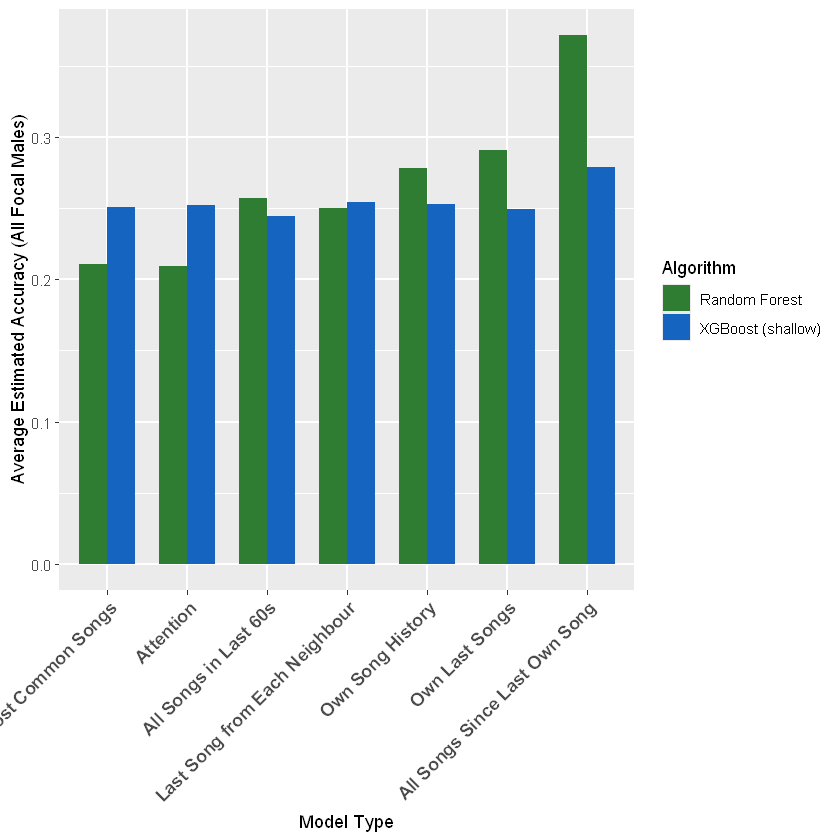

In [127]:
library(tidyverse)

# 1. Automatically find and load all test accuracy CSV files in the workspace
folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
# files = list.files(folder_path, full.names=TRUE)
test_files <- list.files(path = folder_path, pattern = "*test_accuracies.csv", full.names = TRUE)
all_data <- map_dfr(test_files, ~ read_csv(.x, show_col_types = FALSE))

# 2. Standardize model names and filter for the target algorithms & focal males (excluding OPR)
comparison_data <- all_data %>%
  filter(ID != "OPR") %>%
  # Standardize model names to ensure clean matching across file sources
  mutate(
    standardized_model = case_when(
      str_detect(str_to_lower(model), "baseline") ~ "Baseline Classifier",
      str_detect(str_to_lower(model), "own last song") ~ "Own Last Songs",
      str_detect(str_to_lower(model), "own song history") ~ "Own Song History",
      str_detect(str_to_lower(model), "last song from each neighbour") ~ "Last Song from Each Neighbour",
      str_detect(str_to_lower(model), "all songs in last 60") ~ "All Songs in Last 60s",
      str_detect(str_to_lower(model), "all songs since last own song") ~ "All Songs Since Last Own Song",
      str_detect(str_to_lower(model), "most common song") ~ "Most Common Songs",
      str_detect(str_to_lower(model), "attention|true attention") & str_detect(model, "30") ~ "Attention 30s",
      str_detect(str_to_lower(model), "attention|true attention") ~ "Attention",
      str_detect(str_to_lower(model), "own history \\+ time of day") ~ "Own History + Time of Day",
      TRUE ~ model
    ),
    # Ensure model_type cleanly labels Random Forest vs XGBoost
    algorithm = case_when(
      model_type == "Random Forest" ~ "Random Forest",
      model_type == "XGBoost (shallow)" ~ "XGBoost (shallow)",
      TRUE ~ NA_character_
    )
  ) %>%
  filter(!is.na(algorithm)) %>%
  # 3. Calculate average estimated accuracy over all focal males
  group_by(standardized_model, algorithm) %>%
  summarise(
    mean_accuracy = mean(estimated_accuracy, na.rm = TRUE),
    .groups = "drop"
  )

# 4. Define custom colors for Random Forest vs XGBoost
algo_colors <- c(
  "Random Forest" = "#2E7D32",       # Dark Green tone
  "XGBoost (shallow)" = "#1565C0"  # Dark Blue tone
)

# 5. Generate the comparison bar chart
ggplot(comparison_data %>% filter_out(standardized_model %in% c("Own History + Time of Day", "Attention 30s")), aes(x = reorder(standardized_model, mean_accuracy), y = mean_accuracy, fill = algorithm)) +
  geom_col(position = "dodge", width = 0.7) +
  scale_fill_manual(values = algo_colors) +
  theme_grey() +
  labs(
    x = "Model Type",
    y = "Average Estimated Accuracy (All Focal Males)",
    fill = "Algorithm"
  ) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold"),
    panel.grid.major = element_line(color = "white", linewidth = 0.8),
    panel.grid.minor = element_line(color = "white", linewidth = 0.4),
    legend.position = "right"
  )

In [128]:
# # TODO: Throw in baseline classifer
# plot <- ggplot(data = test_accuracies %>% filter(model %in% report_models) %>% filter(model_type %in% c("Baseline", "Random Forest")), aes(x=ID, y=estimated_accuracy, color=model)) +
#     geom_point(size=5) +
#     theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
#     labs(x="Focal Male", y= "Estimated Accuracy", colour="Model Type")
# print(plot)

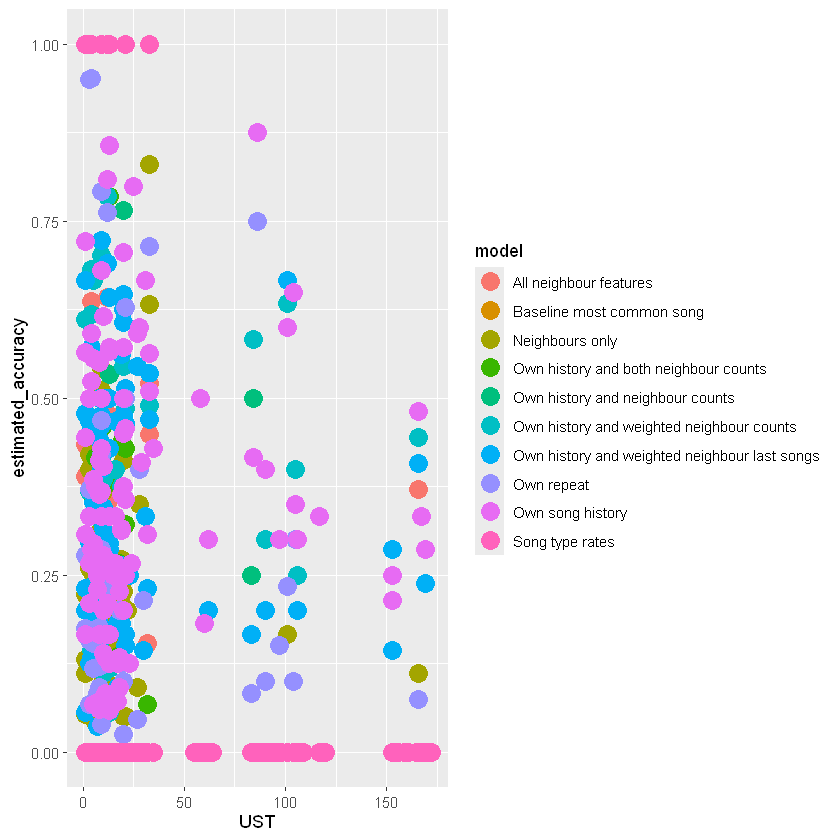

In [129]:

plot <- ggplot(data = song_accuracies, aes(x=UST, y=estimated_accuracy, color=model)) +
    geom_point(size=5)
print(plot)

Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 10 values. Consider specifying shapes manually if you need
  that many of them."
Warning message:
"Removed 768 rows containing missing values or values outside the scale range
(`geom_point()`)."


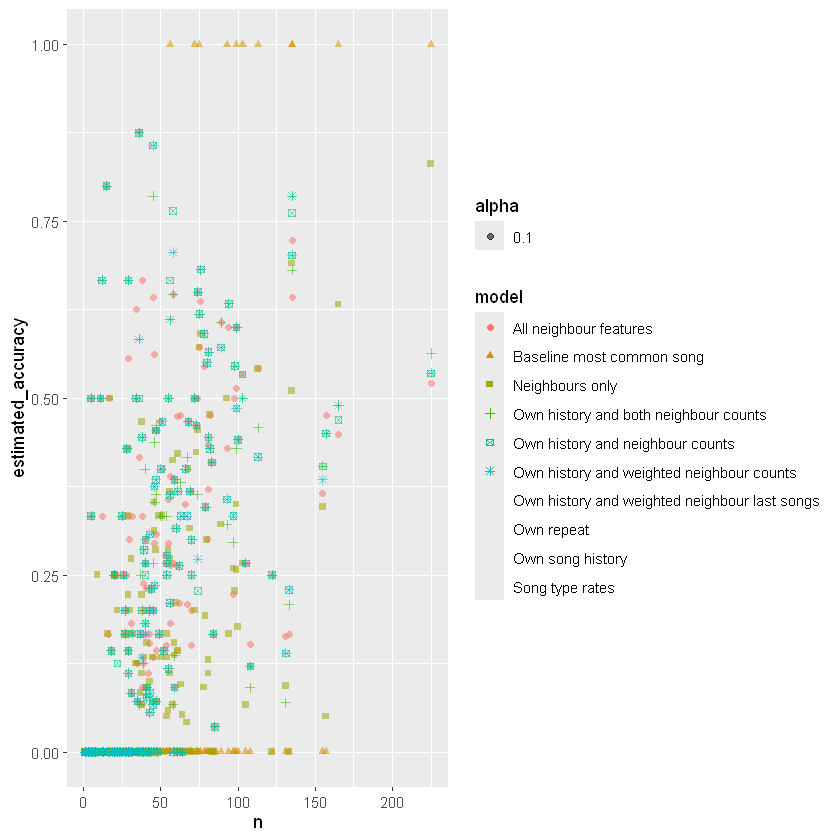

In [130]:
plot <- ggplot(data=song_accuracies) + 
    aes(x=n, y=estimated_accuracy, color=model, shape=model, alpha=0.1) +
    geom_point()
print(plot)

Ignoring unknown labels:
• colour : "Focal Male"


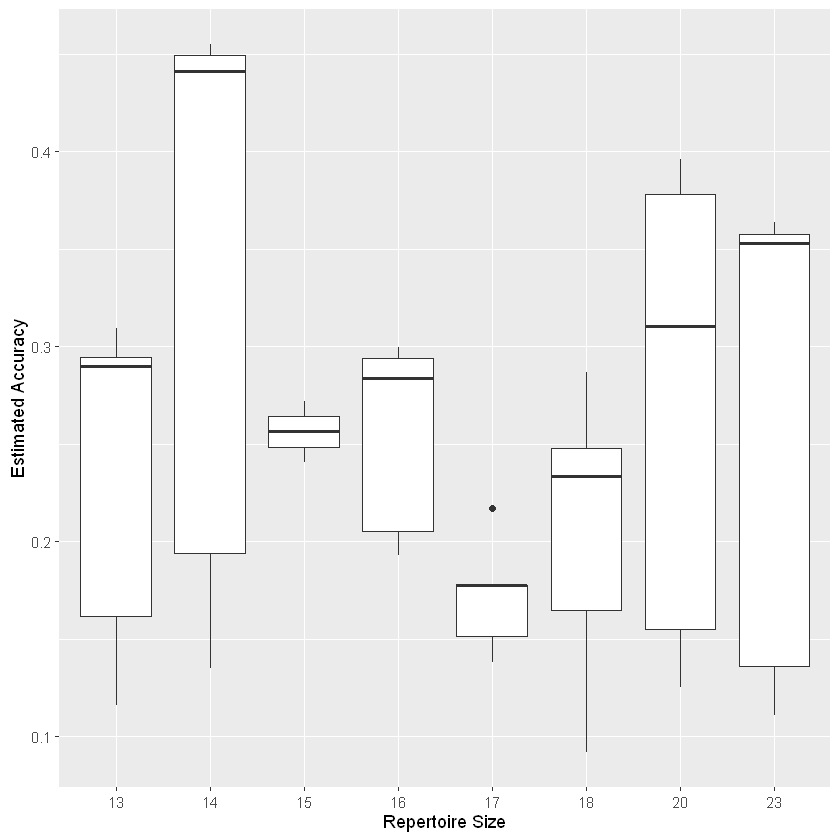

In [131]:
ggplot(test_accuracies %>% filter(model %in% report_models)%>% filter(ID != "OPR") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
    geom_boxplot() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male')

In [132]:
# TODO: Results don't have neighbourhood column
# ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "north") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
#     geom_boxplot() +
#     labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (North Neighbourhood)")

In [133]:
# TODO: Results don't have neighbourhood column
# # ggplot(test_accuracies %>% filter(model %in% report_models) %>% filter(neighbourhood == "centre") %>% mutate(repertoire_size = as.factor(repertoire_size)), aes(x=repertoire_size, y=estimated_accuracy)) +
#     geom_boxplot() +
#     labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Model Accuracy (Centre Neighbourhood)")

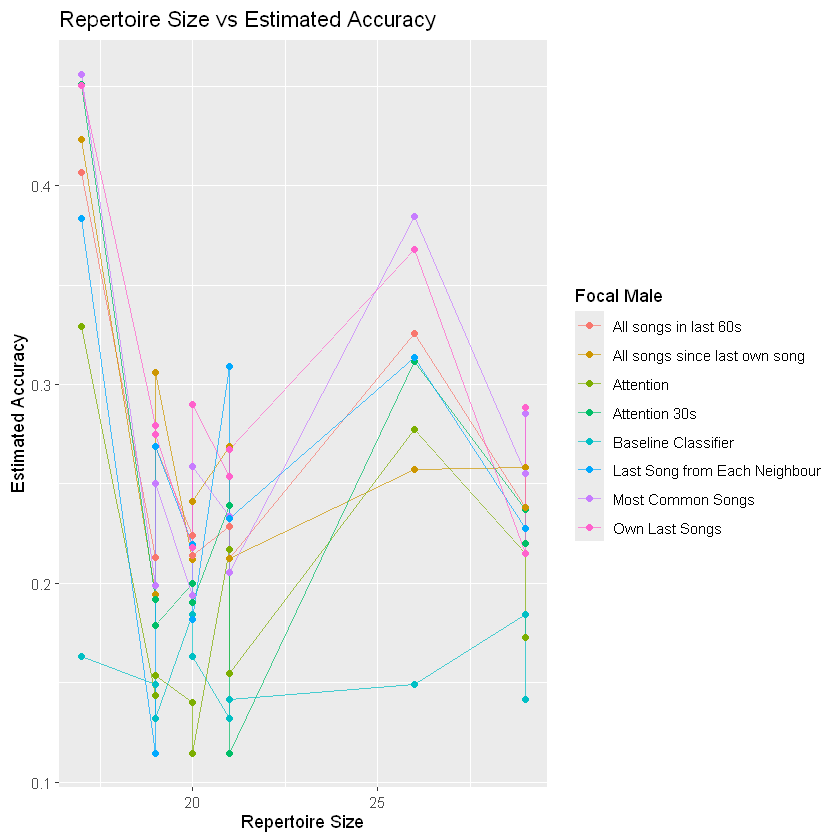

In [134]:
ggplot(test_accuracies_2026 %>% filter(model %in% report_models_2026)%>% filter(ID != "OPR" & model_type %in% c("Baseline", "Random Forest")), aes(x=repertoire_size, y=estimated_accuracy, color=model)) +
    geom_line(alpha=0.7) +
    geom_point() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Estimated Accuracy")

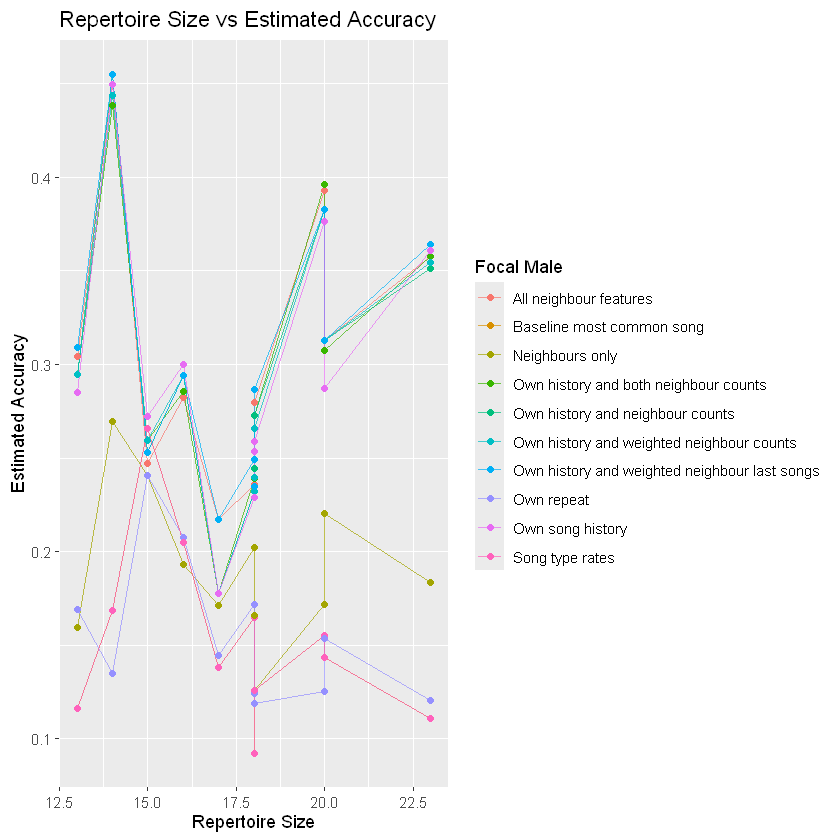

In [135]:
ggplot(test_accuracies %>% filter(model %in% report_models)%>% filter(ID != "OPR"), aes(x=repertoire_size, y=estimated_accuracy, color=model)) +
    geom_line(alpha=0.7) +
    geom_point() +
    labs(x="Repertoire Size", y = "Estimated Accuracy", color='Focal Male', title="Repertoire Size vs Estimated Accuracy")

In [136]:
unique(song_accuracies$model)

[1] "All neighbour features"                       
 [2] "Baseline most common song"                    
 [3] "Neighbours only"                              
 [4] "Own history and both neighbour counts"        
 [5] "Own history and neighbour counts"             
 [6] "Own history and weighted neighbour counts"    
 [7] "Own history and weighted neighbour last songs"
 [8] "Own repeat"                                   
 [9] "Own song history"                             
[10] "Song type rates"

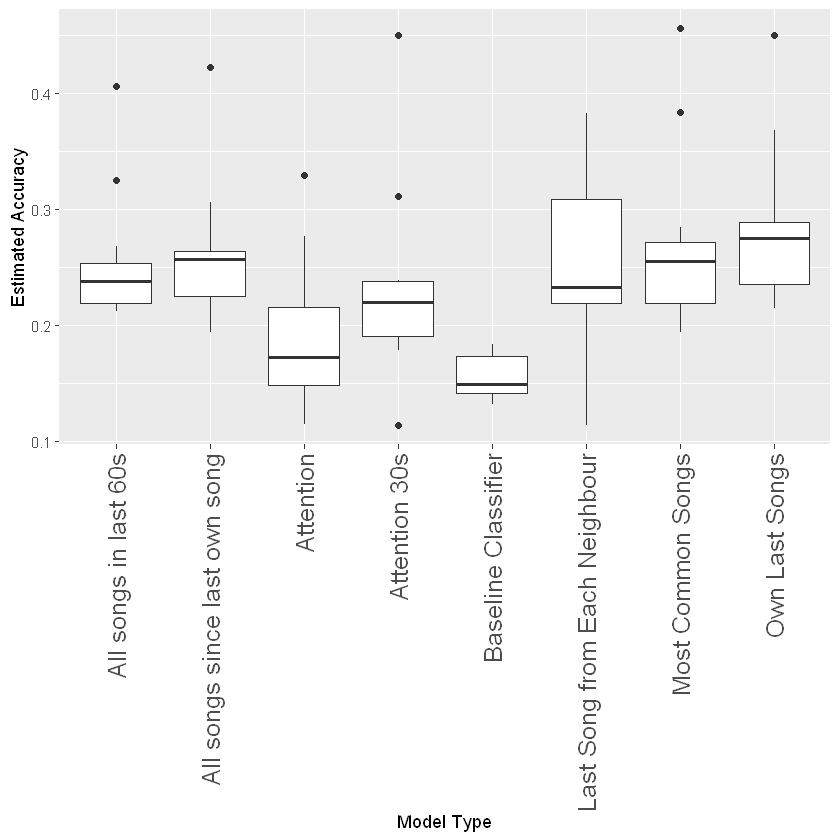

In [137]:
# (Winter 2026) Accuracy distribution of each model type
ggplot(data=test_accuracies_2026 %>% filter(model %in% report_models_2026) %>% filter(ID != "OPR") %>%filter(model_type %in% c("Baseline", "Random Forest"))) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical 
    labs(x="Model Type", y="Estimated Accuracy")

In [138]:
test_accuracies_2026 %>% filter(model=="All songs since last own song" & model_type=="Random Forest")

ID,repertoire_size,estimated_accuracy,model,model_type,neighbourhood,male_number
<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>
DgTbO,29,0.2585139,All songs since last own song,Random Forest,north,5
DgTbO,29,0.2585139,All songs since last own song,Random Forest,centre,6
KLgK,20,0.2121212,All songs since last own song,Random Forest,centre,5
KRDg,26,0.2573290,All songs since last own song,Random Forest,centre,2
LbOW,19,0.1943128,All songs since last own song,Random Forest,north,1
OPR,21,0.2796935,All songs since last own song,Random Forest,NA,NA
RRO,19,0.3062500,All songs since last own song,Random Forest,north,6
RbDgY,21,0.2690355,All songs since last own song,Random Forest,north,2
TbTbLg,20,0.2410714,All songs since last own song,Random Forest,north,4


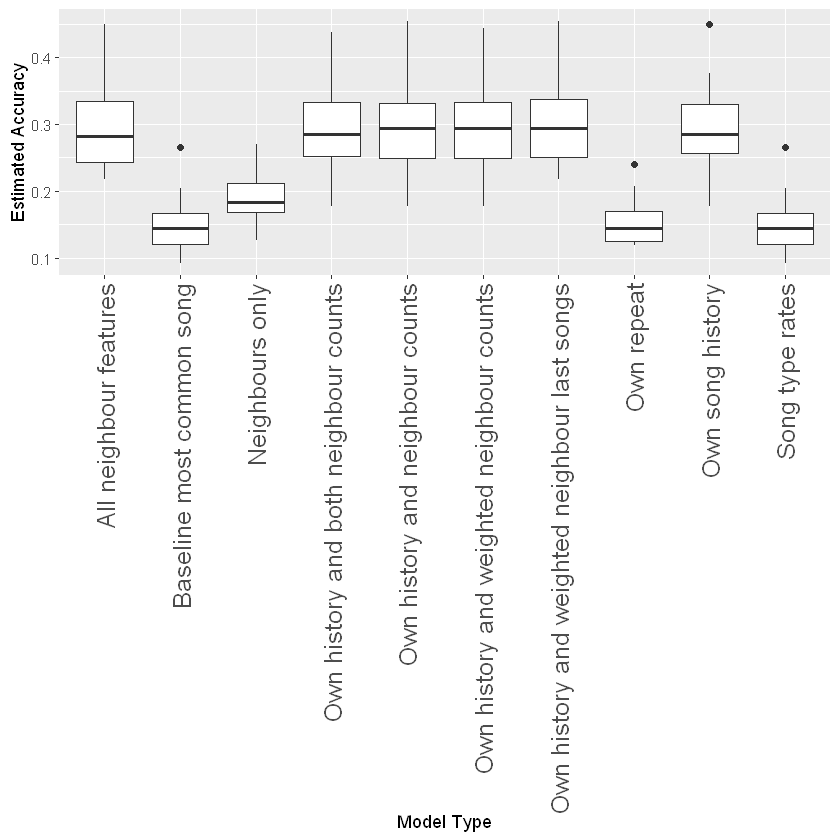

In [139]:
# Accuracy distribution of each model type
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical 
    labs(x="Model Type", y="Estimated Accuracy")

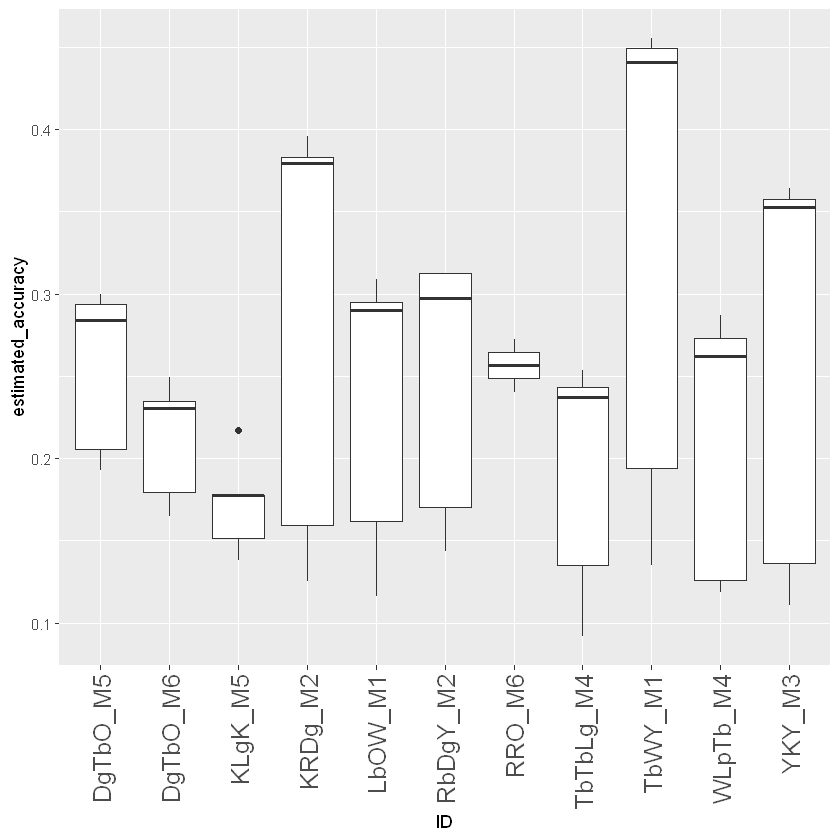

In [140]:
# Accuracy distribution of each focal male
ggplot(data=test_accuracies %>% filter(model %in% report_models)) +
    aes(x=ID, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [141]:
# TODO: Add neighbourhood column
# # Accuracy distribution of each focal male
# ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="north")) +
#     aes(x=ID, y=estimated_accuracy) + 
#     geom_boxplot() +
#     theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [142]:
# TODO: Add neighbourhood column
# # Accuracy distribution of each focal male
# ggplot(data=test_accuracies %>% filter(model %in% report_models, neighbourhood=="centre")) +
#     aes(x=ID, y=estimated_accuracy) + 
#     geom_boxplot() +
#     theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

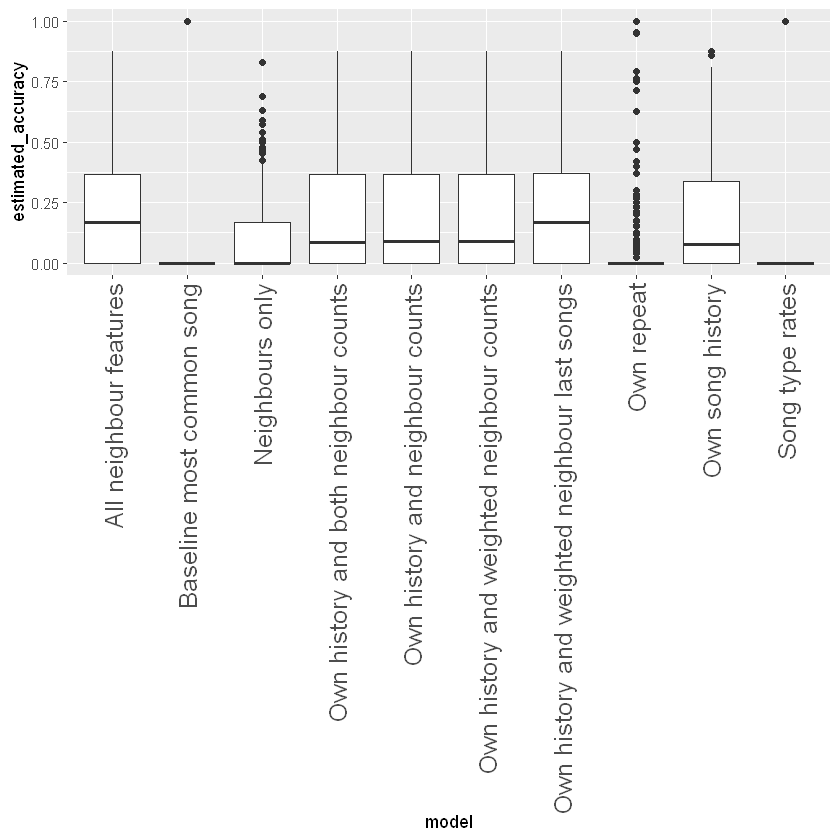

In [143]:
# Accuracy distribution of song types according to models
ggplot(data=song_accuracies) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [144]:
test_accuracies %>% group_by(ID) %>% summarize(mean_accuracy = mean(estimated_accuracy)) %>% arrange(desc(mean_accuracy))

ID,mean_accuracy
<chr>,<dbl>
TbWY_M1,0.3432584
KRDg_M2,0.2920792
YKY_M3,0.2670886
DgTbO_M5,0.2559078
RRO_M6,0.2556962
RbDgY_M2,0.2507692
LbOW_M1,0.2342995
WLpTb_M4,0.2132867
DgTbO_M6,0.2121212


In [145]:
test_accuracies %>% group_by(model) %>% summarize(mean_accuracy = mean(estimated_accuracy)) %>% arrange(desc(mean_accuracy))

model,mean_accuracy
<chr>,<dbl>
Own history and weighted neighbour last songs,0.3053573
All neighbour features,0.3016676
Own history and both neighbour counts,0.2975152
Own history and neighbour counts,0.2973365
Own history and weighted neighbour counts,0.2961234
Own song history,0.2953898
Neighbours only,0.1911994
Own repeat,0.1555622
Baseline most common song,0.1532328


In [146]:
test_accuracies %>% filter(ID != "OPR") %>% group_by(model) %>% summarize(mean_accuracy = mean(estimated_accuracy), neighbourhood=neighbourhood) %>% arrange(desc(mean_accuracy))

ERROR: [1m[33mError[39m in `summarize()`:[22m
[1m[22m[36mℹ[39m In argument: `neighbourhood = neighbourhood`.
[36mℹ[39m In group 1: `model = "All neighbour features"`.
[1mCaused by error:[22m
[1m[22m[33m![39m `neighbourhood` must be size 1, not 11.
[36mℹ[39m To return more or less than 1 row per group, use `reframe()`.
